Let's now test the accuracy of 3 different model in the foreward looking sense. We'll test using Historical Volatility, EWMA, and GARCH(1,1). Let's also compare these model with the VIX, which reflects the options market's expectation of S&P 500 volatility over approximately 30 days. 

**Historical Volatility**

Historical Volatility is the spread in an asset's returns during a specific historical window. It's a backwards looking metric, meaning we can't use it to know exactly what future volatility will be. However, we can use past volatility to estime future volatility and create a baseline for more sophisticated forecasting models. Historical volatility is calculated using the standard deviation of past returns, which can be annualized by multiplying by $\sqrt{252}$, assuming 252 trading days in a year.

$$
\sigma_y = \sqrt{252} \times \sigma_d
$$

To use historical volatility as a forecast, we use the historical volatility today to estimate the volatility in the future. Pretend the lookback window is 21 days. We use the past 21 days average vol and assign it to today, then we use today's assigned vol as our estimate for tomorrow's volatility.

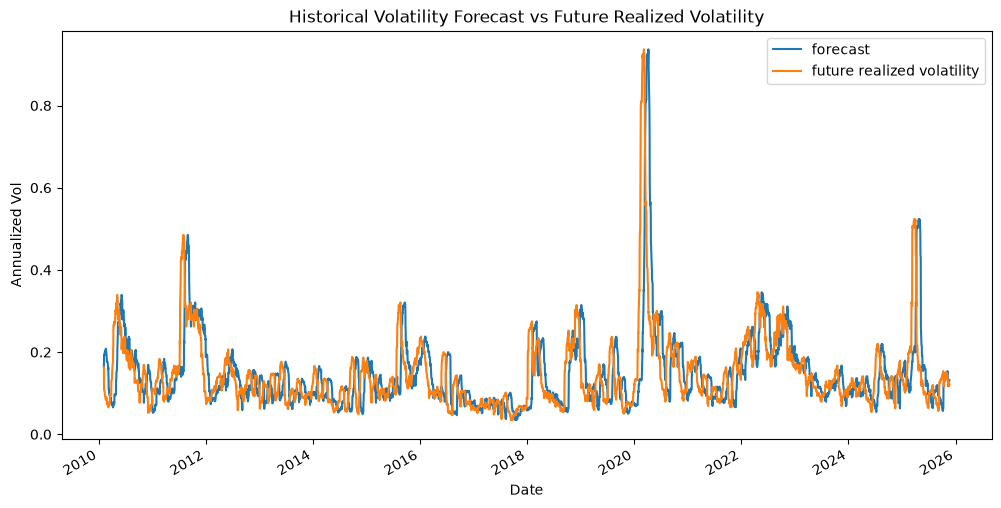

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv(
    "cleaned_prices.csv", index_col=0, parse_dates=True
).squeeze("columns")

log_returns = pd.read_csv(
    'log_return.csv', index_col=0, parse_dates=True
).squeeze("columns")

window = 21

forecast = log_returns.rolling(window).std() * np.sqrt(252)

future_realized_vol = (
    log_returns.rolling(window).std() * np.sqrt(252)
).shift(-window)   # moves values backwards in time by (window) days so
                    # we can compare to our forecast

comparison =  pd.DataFrame({
    'forecast': forecast,
    'future realized volatility': future_realized_vol
}).dropna()

comparison.plot(figsize=(12,6))

plt.title('Historical Volatility Forecast vs Future Realized Volatility')
plt.xlabel('Date')
plt.ylabel('Annualized Vol')
plt.show()

As one can tell, this method isn't very sophisticated or accurate, and can sometimes have large discrepancies.

**EMWA (Exponentially Weighted Moving Average)**

This model is similar to the historical volatility model in that it used past data to estimate future volatility. The difference is in how it averages the previous days. EMWA gives more weight to recent observations, and tapers the weighting exponentially. The equation is as follows:
$$
\sigma_t^2 = \alpha r_{t-1}^2 + (1 - \alpha) \sigma_{t-1}^2
$$

Where:
- $\alpha$ smoothing parameter between zero and one. A higher $\alpha$ means the average reacts quicker to new data.
- $\sigma_t^2$ current estimated variance
- $\sigma_t^2$ previous day's variance
- $r_{t-1}^2$ previous day's squared return

Choosing the alpha value requires some descretion, leaving room for improvement by the GARCH(1,1) model.


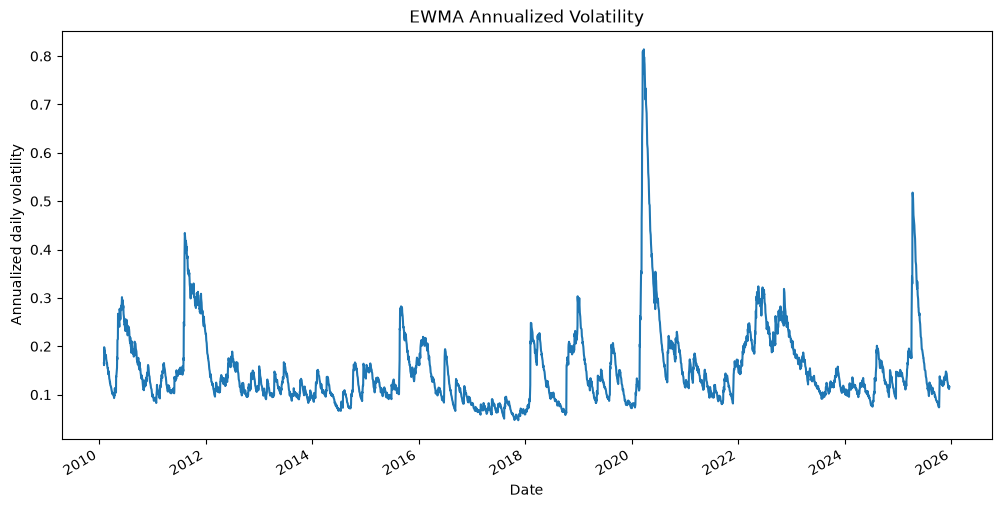

In [30]:
alpha = 0.06

ewma_variance = pd.Series(index=log_returns.index, dtype=float)

ewma_variance.iloc[20] = log_returns.iloc[:21].var()

for t in range(21, len(log_returns)):
    ewma_variance.iloc[t] = (
        alpha * log_returns.iloc[t - 1] ** 2
        + (1 - alpha) * ewma_variance.iloc[t - 1]
    )

ewma_vol = np.sqrt(ewma_variance) * np.sqrt(252)

ewma_vol.plot(figsize=(12,6))

plt.title('EWMA Annualized Volatility')
plt.ylabel('Annualized daily volatility')
plt.xlabel('Date')
plt.show()

**GARCH(1,1) (Generalized Autoregressive Conditional Heteroskedasticity)**

The GARCH(1,1) model's competitive advantage is that it statistically captures past shocks and volatility clustering to improve the forecast.